# 05 原子の抽出と元素の分類 / Atom tracing and species classification

三次元像から，原子の位置（**原子のトレース**）と元素を決めます．

We determine the atomic positions (**atom tracing**) and the species from the 3D volume.

1. **原子の抽出 / Tracing**：三次元像の局所的な極大を原子の候補とし，周りの重心からピクセルより細かい位置を求めます．最近接原子間距離より近い極大は同じ原子とみなします．
   Local maxima of the volume are taken as atom candidates, refined to sub-pixel positions by a local centre of mass. Maxima closer than the nearest-neighbour distance are treated as one atom.
2. **元素の分類 / Classification**：原子のまわりの強度の和は重い元素ほど大きくなります．その分布を 2 つのグループに分けます（k-means 法）．
   The integrated intensity around an atom is larger for heavier elements; its distribution is split into two groups (k-means).
3. **正解との比較 / Comparison**：正解の原子と 1 対 1 に対応させ，見つけた数・見落とし・誤検出・位置の誤差・元素の正答率を数えます．
   Atoms are matched one-to-one with the ground truth to count detections, misses, false detections, position errors and species accuracy.

実験では正解がわからないので，3 の代わりに，原子モデルから計算した投影像と測定像を比べたり，シミュレーションで誤差を見積もったりします．

In experiments the answer is unknown; instead, projections calculated from the atomic model are compared with the measured ones, and errors are estimated by simulations like this one.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # リポジトリの最上位 / repository root
sys.path.insert(0, str(ROOT / "src"))     # src/ のパッケージを使う / use the packages in src/
DATA = ROOT / "data"                      # データの保存先 / where data are saved
DATA.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

In [2]:
from aet_tools import Particle, find_atoms, classify_atoms, match_atoms
INPUT = "tilt_series.npz"     # 02 で位置合わせしたデータなら / data aligned in 02: "tilt_series_aligned.npz"
d = np.load(DATA / INPUT)
projections, theta = d["projections"], d["theta"]
n, pixel_size = int(d["n"]), float(d["pixel_size"])
particle = Particle.from_saved(d)
print("projections:", projections.shape, " tilt range: %.1f to %.1f deg" % (theta.min(), theta.max()))
volumes = {"GENFIRE": np.load(DATA / "genfire.npy"), "RESIRE": np.load(DATA / "resire.npy")}
# 配列の添字を回転中心からの座標に直すための中心（04 を参照）
# centre used to convert array indices to coordinates about the rotation centre (see 04)
centre = {"GENFIRE": n / 2, "RESIRE": (n - 1) / 2}
print(particle.summary())

projections: (96, 96, 57)  tilt range: -70.0 to 70.0 deg
959 atoms (Fe 501, Pt 458), diameter about 2.9 nm, atom sigma 0.50 Å, box 96^3 px (0.40 Å/px, 3.8 nm wide)


## 1. 原子の抽出 / Atom tracing

fcc の最近接原子間距離は a/√2（FePt では約 2.7 Å）です．その 0.8 倍より近い極大は同じ原子とみなします．

The nearest-neighbour distance in fcc is a/√2 (about 2.7 Å for FePt). Maxima closer than 0.8 times this are merged.

**像を鋭くしてから探す / Sharpen before searching**：原子の像には広がりがあるので，明るい Pt 原子のすそに隣の暗い Fe 原子が乗ると，Fe 原子は極大になりません．そこで，原子の像の幅（σ）程度のガウシアンのラプラシアンで像を鋭くしてから極大を探します（`sharpen_sigma_px`）．原子ごとの強度は元の像で求めます．

Atoms have a finite width, so a dim Fe atom sitting on the tail of a bright Pt neighbour is not a local maximum. The volume is therefore sharpened with a Laplacian of Gaussian of about the atom width (σ) before searching for maxima (`sharpen_sigma_px`). The per-atom intensity is still measured on the original volume.

**軽い原子に注意 / Watch out for light atoms**：HAADF 像の強度は原子番号のおよそ 1.7 乗に比例するので，Fe 原子は Pt 原子の 1/6 程度の明るさしかありません．最大値の 10% といったしきい値で極大を選ぶと，Fe 原子の多くを落としてしまいます．そこで，しきい値は低く（最大値の 3%）して候補を多めに取り，次の節でノイズを除きます．

HAADF intensity scales roughly as Z<sup>1.7</sup>, so an Fe atom is only about 1/6 as bright as a Pt atom. Selecting maxima above, say, 10% of the maximum loses many Fe atoms. The threshold is therefore set low (3% of the maximum) to collect plenty of candidates, and noise is removed in the next step.

In [3]:
a = 3.85                                   # 格子定数 / lattice constant (Å)
nn_px = a / np.sqrt(2) / pixel_size        # 最近接原子間距離 / nearest-neighbour distance (px)
candidates = {}
for name, vol in volumes.items():
    pos, inten = find_atoms(vol, min_distance_px=0.8 * nn_px, threshold=0.03,
                            sharpen_sigma_px=particle.sigma_px)   # 原子の像の幅 / atom width (px)
    candidates[name] = (pos - centre[name], inten)
    print("%-8s %d candidates (ground truth: %d atoms)" % (name, len(pos), len(particle)))

GENFIRE  975 candidates (ground truth: 959 atoms)


RESIRE   959 candidates (ground truth: 959 atoms)


## 2. ノイズの除去と元素の分類 / Removing noise and classifying species

各候補のまわりの強度の和（積分強度）のヒストグラムです（横軸は対数）．ノイズの極大（左端）・Fe・Pt の 3 つの山に分かれます．

Histogram of the integrated intensity around each candidate (log scale). It splits into three peaks: noise maxima (far left), Fe and Pt.

- **ノイズの除去 / noise**：典型的な Fe 原子の半分より弱い候補は原子ではないとして除きます（点線）． / candidates weaker than half a typical Fe atom are rejected (dotted line).
- **元素の分類 / species**：残りを 2 つのグループに分けます（k-means 法，破線）． / the rest are split into two groups (k-means, dashed line).

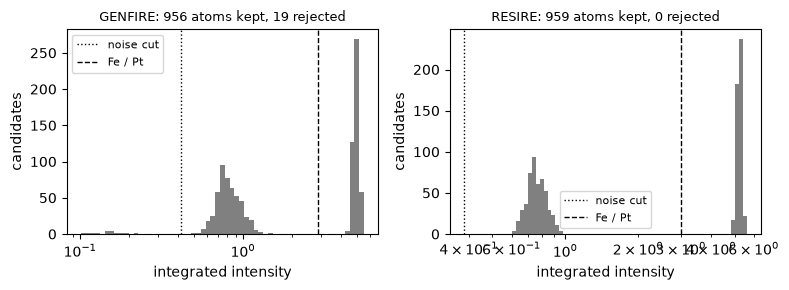

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
found, labels = {}, {}
for ax, (name, (pos, inten)) in zip(axes, candidates.items()):
    lab, thr, noise_thr = classify_atoms(inten, min_fraction=0.5)
    keep = lab >= 0
    found[name], labels[name] = (pos[keep], inten[keep]), lab[keep]
    bins = np.logspace(np.log10(max(inten.min(), 1e-3 * inten.max())), np.log10(inten.max()), 60)
    ax.hist(inten, bins=bins, color="0.5")
    ax.axvline(noise_thr, color="k", ls=":", lw=1, label="noise cut")
    ax.axvline(thr, color="k", ls="--", lw=1, label="Fe / Pt")
    ax.set_xscale("log"); ax.legend(fontsize=8)
    ax.set_title("%s: %d atoms kept, %d rejected" % (name, keep.sum(), (~keep).sum()), fontsize=9)
    ax.set_xlabel("integrated intensity"); ax.set_ylabel("candidates")
fig.tight_layout(); plt.show()

## 3. 正解との比較 / Comparison with the ground truth

正解の原子から 0.5 × 最近接原子間距離 以内にある原子を対応させます．02 で位置合わせしたデータでは粒子全体が少し平行移動しているので（位置合わせでは決まらない成分），その平行移動を求めて差し引いてから比べます（`remove_offset=True`）．

An atom is matched to a ground-truth atom if it lies within 0.5 × the nearest-neighbour distance. With the data aligned in 02 the whole particle is slightly translated (the part alignment cannot fix), so that translation is estimated and removed first (`remove_offset=True`).

In [5]:
print("%-8s %7s %7s %7s %11s %9s" % ("", "found", "missed", "false", "RMSD", "species"))
matches = {}
for name, (pos, inten) in found.items():
    m = match_atoms(particle.positions, pos, particle.species, labels[name],
                    tolerance_px=0.5 * nn_px, pixel_size=pixel_size, remove_offset=True)
    matches[name] = m
    print("%-8s %7d %7d %7d %8.1f pm %8.1f %%" % (name, m["found"], m["missed"], m["false"],
                                                m["rmsd_pm"], 100 * m["species_accuracy"]))

           found  missed   false        RMSD   species
GENFIRE      956       3       0     14.5 pm    100.0 %
RESIRE       959       0       0     12.8 pm    100.0 %


位置の誤差の分布です．AET の実験では，数十 pm の精度で原子の位置が決められています．

Distribution of the position errors. AET experiments determine atomic positions to a precision of a few tens of picometres.

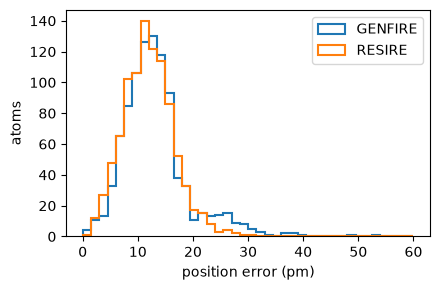

In [6]:
plt.figure(figsize=(4.5, 3))
for name, m in matches.items():
    plt.hist(m["displacement_pm"], bins=40, range=(0, 60), histtype="step", lw=1.5, label=name)
plt.xlabel("position error (pm)"); plt.ylabel("atoms"); plt.legend(); plt.tight_layout(); plt.show()

見落とした原子と誤検出した原子が粒子のどこにあるかを見てみます（粒子の中心からの距離）．誤検出が粒子の外側（サポートの内側）に出ているか，内部に出ているかで，原因の見当がつきます．

Where are the missed and false atoms (distance from the particle centre)? Whether false detections lie outside the particle (but inside the support) or inside it hints at their cause.

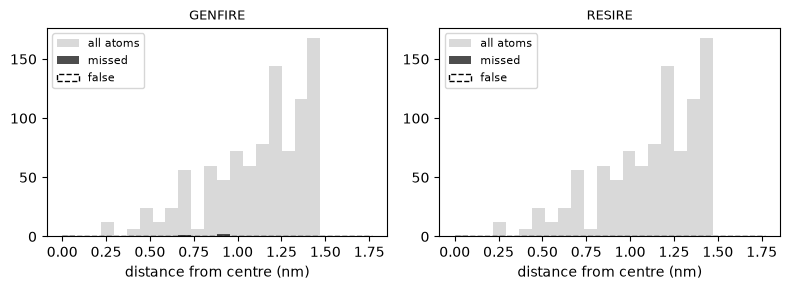

In [7]:
r_true = np.linalg.norm(particle.positions, axis=1) * pixel_size / 10
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (name, m) in zip(axes, matches.items()):
    missed = np.setdiff1d(np.arange(len(particle)), m["pairs"][:, 0])
    pos = found[name][0]
    false = np.setdiff1d(np.arange(len(pos)), m["pairs"][:, 1])
    r_false = np.linalg.norm(pos[false], axis=1) * pixel_size / 10
    bins = np.linspace(0, r_true.max() + 0.3, 25)
    ax.hist(r_true, bins, color="0.85", label="all atoms")
    ax.hist(r_true[missed], bins, color="0.3", label="missed")
    ax.hist(r_false, bins, histtype="step", color="k", ls="--", label="false")
    ax.set_title(name, fontsize=9); ax.set_xlabel("distance from centre (nm)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. 原子モデルの保存 / Saving the atomic model

求めた原子モデルを，原子の可視化ソフト（VESTA, OVITO など）で開ける XYZ 形式で保存します．

The atomic models are saved in XYZ format, which atom viewers such as VESTA and OVITO can open.

In [8]:
for name, (pos, inten) in found.items():
    xyz = pos * pixel_size                                  # Å
    elem = np.array(particle.names)[labels[name]]
    path = DATA / ("atoms_%s.xyz" % name.lower())
    with open(path, "w") as f:
        f.write("%d\n%s reconstruction, positions in angstrom\n" % (len(xyz), name))
        for e, (x, y, z) in zip(elem, xyz):
            f.write("%s %.3f %.3f %.3f\n" % (e, x, y, z))
    print("saved:", path.relative_to(ROOT).as_posix())

saved: data/atoms_genfire.xyz
saved: data/atoms_resire.xyz


### やってみよう / Try it

- 01 で `COUNTS_PER_ATOM` を 50 に下げる（電子線量を減らす）と，粒子の内部の Fe 原子がノイズに埋もれて見落とされ始めます．どこの原子が見落とされるか，上の図で確かめましょう．
  Lower `COUNTS_PER_ATOM` to 50 in 01 (lower dose): Fe atoms inside the particle start to drown in the noise. Check in the figure above which atoms are missed.
- 01 で `atomic_numbers=(46, 78)`（PdPt）にすると，ヒストグラムの 2 つの山が近づきます．
  With `atomic_numbers=(46, 78)` (PdPt) in 01, the two peaks of the histogram move closer.
- `sharpen_sigma_px=None`（鋭くしない）にすると，どの原子が見落とされるでしょうか．
  With `sharpen_sigma_px=None` (no sharpening), which atoms are missed?
- `find_atoms` の `threshold` を 0.1 に上げると，どの元素の原子が見落とされるでしょうか．`classify_atoms` の `min_fraction` を変えると，見落としと誤検出の数はどう変わるでしょうか．
  Raise `threshold` in `find_atoms` to 0.1: atoms of which element are lost? How do misses and false detections change with `min_fraction` in `classify_atoms`?
- 03・04・05 の最初のセルで `INPUT = "tilt_series_aligned.npz"` とすると，02 で位置合わせしたデータで同じ評価ができます．
  Set `INPUT = "tilt_series_aligned.npz"` in 03, 04 and 05 to evaluate the data aligned in 02 in the same way.
- GENFIRE と RESIRE で誤検出の数が違うのはなぜでしょうか（ヒント：測定していないフーリエ成分の扱い）．
  Why do GENFIRE and RESIRE give different numbers of false detections? (Hint: how each treats the unmeasured Fourier components.)

## 参考文献 / References

- J. Miao, P. Ercius, S. J. L. Billinge, *Science* **353**, aaf2157 (2016). （AET の総説 / review of AET）
- A. Pryor Jr. *et al.*, *Sci. Rep.* **7**, 10409 (2017). （GENFIRE）
- M. Pham *et al.*, *Sci. Rep.* **13**, 5624 (2023). （RESIRE）
- Y. Yang *et al.*, *Nature* **542**, 75 (2017). （FePt ナノ粒子の AET / AET of an FePt nanoparticle）